# 01 · Exploratory Data Analysis
**Question:** What drives patient satisfaction with medicines sold on 1mg?

This notebook reads `data/processed/features.pkl` (made by `src/parse.py` and `src/features.py`)
and answers seven questions:

1. How are review percentages distributed?
2. Does dosage form matter?
3. Which therapeutic areas are rated best and worst?
4. Do more side effects mean lower satisfaction?
5. Which specific side effects are linked to poor ratings?
6. Do manufacturers differ?
7. **Same salt, different brand:** does the brand matter when the molecule is identical?

Charts are also saved to `reports/figures/` for the README.

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether the notebook runs from /notebooks or the root
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

bundle = pd.read_pickle(ROOT / "data" / "processed" / "features.pkl")
df = bundle["df"]
feature_cols = bundle["feature_cols"]

plt.rcParams.update({"figure.figsize": (10, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

def save(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

print(f"{len(df):,} medicines | {df['composition_clean'].nunique():,} compositions | "
      f"{df['manufacturer'].nunique():,} manufacturers")
df[["medicine_name", "composition_clean", "dosage_form", "primary_category",
    "excellent_review", "average_review", "poor_review", "net_score"]].head()

11,735 medicines | 3,355 compositions | 759 manufacturers


,medicine_name,composition_clean,dosage_form,primary_category,excellent_review,average_review,poor_review,net_score
0,Avastin 400mg Injection,bevacizumab (400mg),injection,cancer,22,56,22,0
1,Augmentin 625 Duo Tablet,amoxycillin (500mg) + clavulanic acid (125mg),tablet,antibiotic,47,35,18,29
2,Azithral 500 Tablet,azithromycin (500mg),tablet,antibiotic,39,40,21,18
3,Ascoril LS Syrup,ambroxol (30mg/5ml) + guaifenesin (50mg/5ml) +...,syrup,respiratory,24,41,35,-11
4,Aciloc 150 Tablet,ranitidine (150mg),tablet,gastro,34,37,29,5


## 1. How are review percentages distributed?

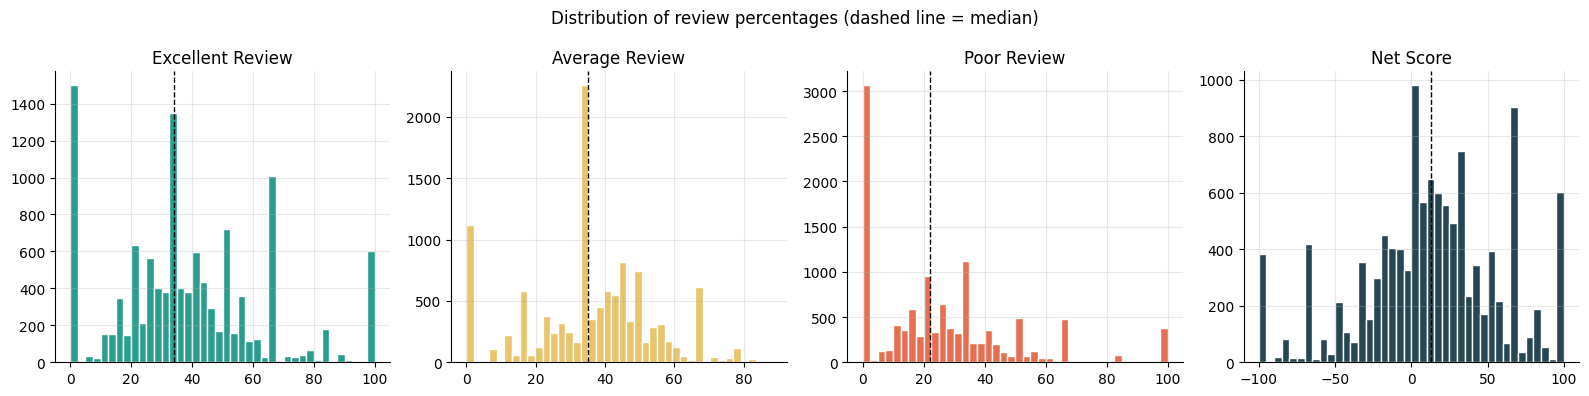

,excellent_review,average_review,poor_review,net_score
count,11735.0,11735.0,11735.0,11735.0
mean,38.5,35.8,25.7,12.8
std,25.2,18.3,23.9,45.6
min,0.0,0.0,0.0,-100.0
25%,22.0,27.0,0.0,-12.0
50%,34.0,35.0,22.0,13.0
75%,51.0,47.0,35.0,42.0
max,100.0,88.0,100.0,100.0


In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col, color in zip(axes,
                          ["excellent_review", "average_review", "poor_review", "net_score"],
                          ["#2a9d8f", "#e9c46a", "#e76f51", "#264653"]):
    ax.hist(df[col], bins=40, color=color, edgecolor="white")
    ax.set_title(col.replace("_", " ").title())
    ax.axvline(df[col].median(), color="black", ls="--", lw=1)
fig.suptitle("Distribution of review percentages (dashed line = median)")
save("01_review_distributions")

df[["excellent_review", "average_review", "poor_review", "net_score"]].describe().round(1)

**What to look for:** spikes at round numbers (0, 50, 100) usually mean medicines with very few reviews.
Note this as a limitation, because the dataset has no review counts.

## 2. Does dosage form matter?

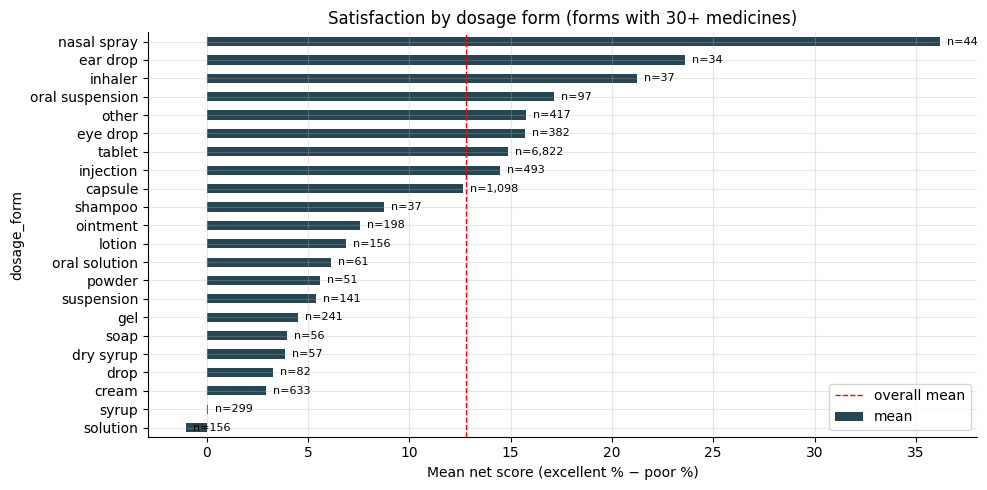

,mean,median,count
dosage_form,,,
solution,-1.0,-5.5,156
syrup,0.1,1.0,299
cream,2.9,0.0,633
drop,3.3,1.5,82
dry syrup,3.8,11.0,57
soap,3.9,0.0,56
gel,4.5,1.0,241
suspension,5.4,4.0,141
powder,5.6,3.0,51


In [14]:
form_stats = (df.groupby("dosage_form")["net_score"]
                .agg(["mean", "median", "count"])
                .query("count >= 30")
                .sort_values("mean"))

ax = form_stats["mean"].plot.barh(color="#264653")
for i, (m, n) in enumerate(zip(form_stats["mean"], form_stats["count"])):
    ax.text(m, i, f"  n={n:,}", va="center", fontsize=8)
ax.axvline(df["net_score"].mean(), color="red", ls="--", lw=1, label="overall mean")
ax.set_xlabel("Mean net score (excellent % − poor %)")
ax.set_title("Satisfaction by dosage form (forms with 30+ medicines)")
ax.legend()
save("02_dosage_form")
form_stats.round(1)

## 3. Which therapeutic areas are rated best and worst?

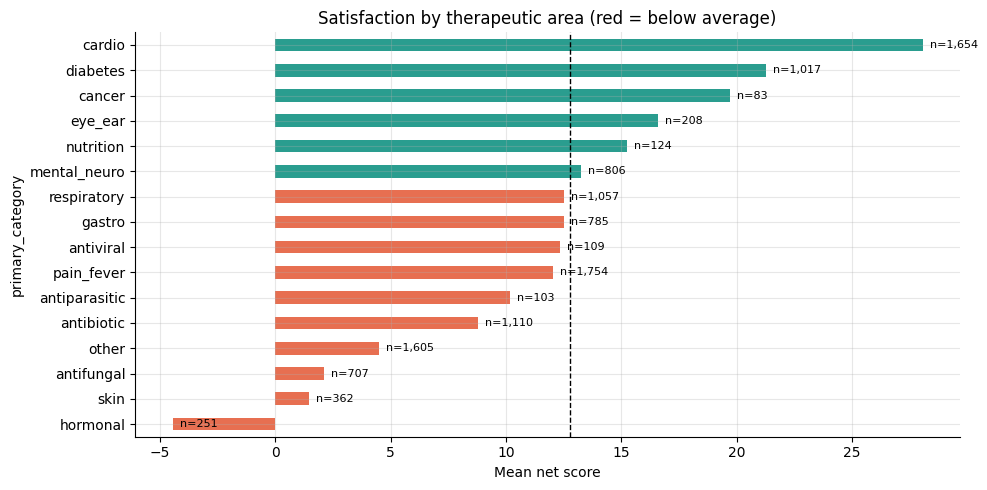

,mean,count
primary_category,,
hormonal,-4.5,251
skin,1.4,362
antifungal,2.1,707
other,4.5,1605
antibiotic,8.8,1110
antiparasitic,10.2,103
pain_fever,12.0,1754
antiviral,12.3,109
gastro,12.5,785


In [15]:
cat_stats = (df.groupby("primary_category")["net_score"]
               .agg(["mean", "count"]).sort_values("mean"))

colors = ["#e76f51" if m < df["net_score"].mean() else "#2a9d8f" for m in cat_stats["mean"]]
ax = cat_stats["mean"].plot.barh(color=colors)
for i, (m, n) in enumerate(zip(cat_stats["mean"], cat_stats["count"])):
    ax.text(m, i, f"  n={n:,}", va="center", fontsize=8)
ax.axvline(df["net_score"].mean(), color="black", ls="--", lw=1)
ax.set_xlabel("Mean net score")
ax.set_title("Satisfaction by therapeutic area (red = below average)")
save("03_therapeutic_area")
cat_stats.round(1)

## 4. Do more side effects mean lower satisfaction?

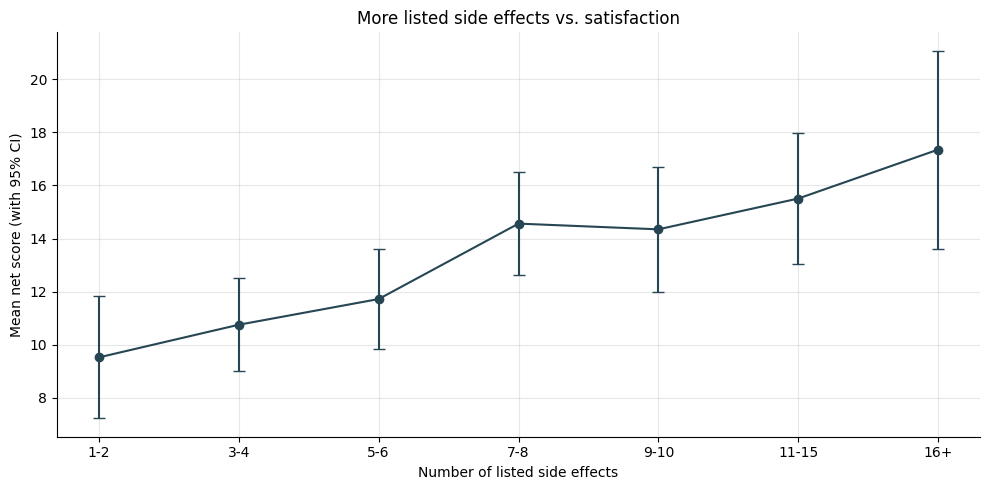

Spearman correlation (n_side_effects vs net_score): 0.056


,mean,sem,count
se_bucket,,,
1-2,9.5,1.2,1359
3-4,10.8,0.9,2458
5-6,11.7,1.0,2447
7-8,14.6,1.0,2124
9-10,14.3,1.2,1424
11-15,15.5,1.3,1393
16+,17.4,1.9,530


In [16]:
bins = [-1, 0, 2, 4, 6, 8, 10, 15, 100]
labels = ["0", "1-2", "3-4", "5-6", "7-8", "9-10", "11-15", "16+"]
df["se_bucket"] = pd.cut(df["n_side_effects"], bins=bins, labels=labels)

se_stats = df.groupby("se_bucket", observed=True)["net_score"].agg(["mean", "sem", "count"])

fig, ax = plt.subplots()
ax.errorbar(range(len(se_stats)), se_stats["mean"], yerr=1.96 * se_stats["sem"],
            marker="o", capsize=4, color="#264653")
ax.set_xticks(range(len(se_stats)), se_stats.index)
ax.set_xlabel("Number of listed side effects")
ax.set_ylabel("Mean net score (with 95% CI)")
ax.set_title("More listed side effects vs. satisfaction")
save("04_side_effect_count")

corr = df[["n_side_effects", "net_score"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (n_side_effects vs net_score): {corr:.3f}")
se_stats.round(1)

## 5. Which specific side effects are linked to poor ratings?
For each common side effect: mean net score of medicines that list it minus those that don't.

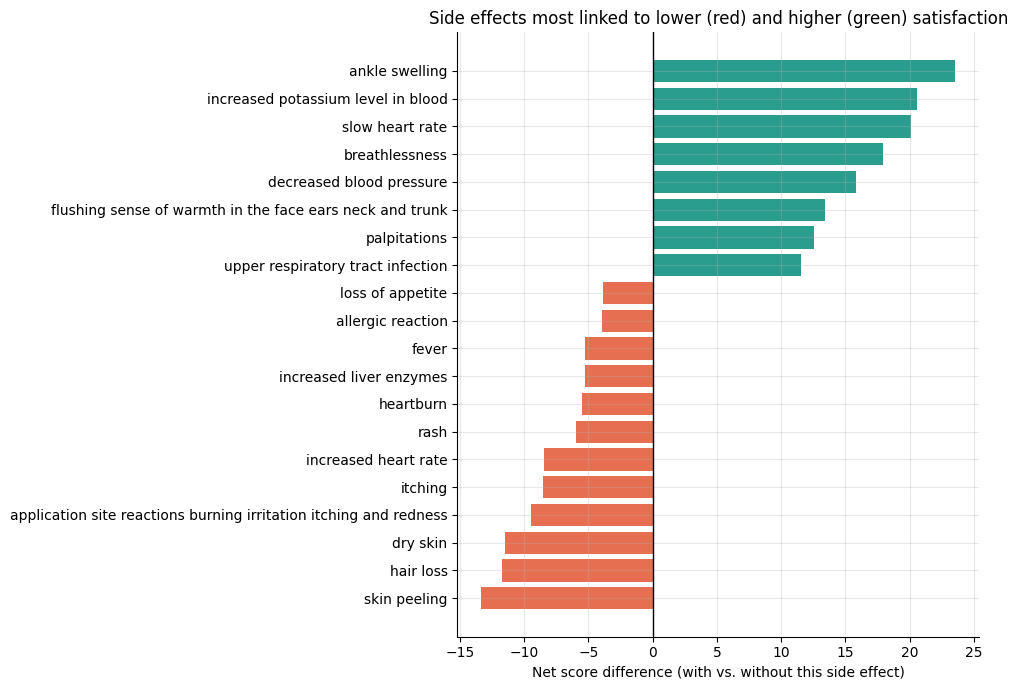

                             mean  count
se_has_serious                          
no serious side effects      12.0   9407
lists a serious side effect  15.8   2328


In [17]:
se_cols = [c for c in feature_cols if c.startswith("se_")
           and c not in ("se_serious_count", "se_mild_count", "se_has_serious")]

rows = []
for c in se_cols:
    has = df[c] == 1
    if has.sum() >= 30:
        rows.append({"side_effect": c[3:].replace("_", " "),
                     "n": int(has.sum()),
                     "gap": df.loc[has, "net_score"].mean() - df.loc[~has, "net_score"].mean()})
gaps = pd.DataFrame(rows).sort_values("gap")

show = pd.concat([gaps.head(12), gaps.tail(8)])
colors = ["#e76f51" if g < 0 else "#2a9d8f" for g in show["gap"]]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(show["side_effect"], show["gap"], color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Net score difference (with vs. without this side effect)")
ax.set_title("Side effects most linked to lower (red) and higher (green) satisfaction")
save("05_side_effect_gaps")

# Serious vs. mild side effects
print(df.groupby("se_has_serious")["net_score"].agg(["mean", "count"])
        .rename(index={0: "no serious side effects", 1: "lists a serious side effect"}).round(1))

**Careful with interpretation:** this is association, not causation. Side effects are tied to
the therapeutic area (e.g. drowsiness is common in mental-health drugs), so the model in
`03_modeling` is needed to separate these effects.

## 6. Do manufacturers differ?

Manufacturers with 30+ products: 67


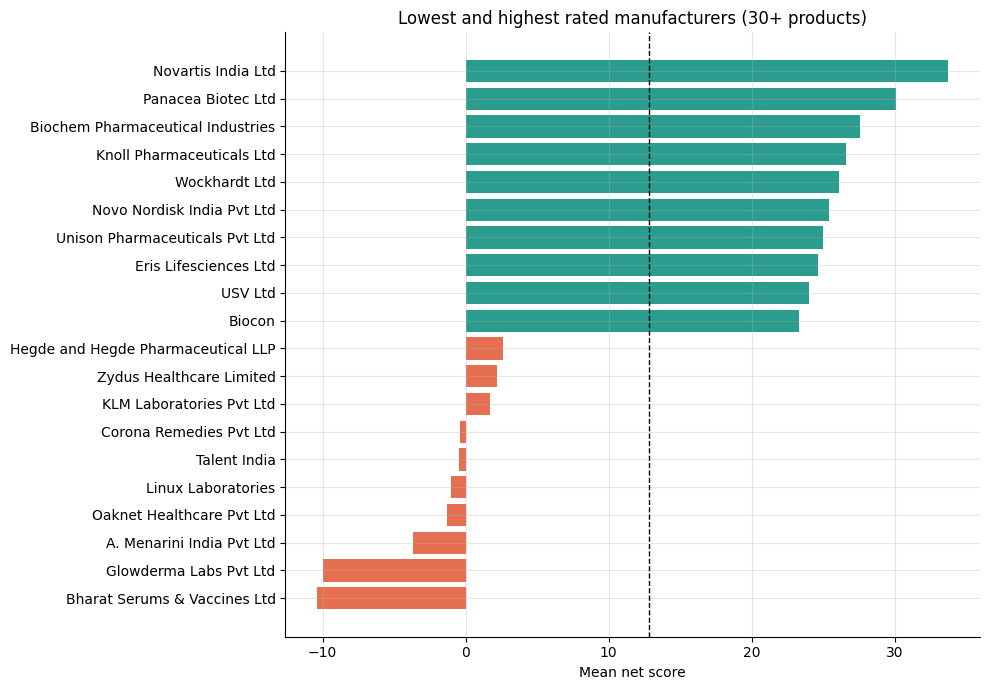

In [18]:
mfr = (df.groupby("manufacturer")["net_score"]
         .agg(["mean", "count"]).query("count >= 30").sort_values("mean"))
print(f"Manufacturers with 30+ products: {len(mfr)}")

show = pd.concat([mfr.head(10), mfr.tail(10)])
colors = ["#e76f51"] * min(10, len(mfr)) + ["#2a9d8f"] * (len(show) - min(10, len(mfr)))
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(show.index, show["mean"], color=colors)
ax.axvline(df["net_score"].mean(), color="black", ls="--", lw=1)
ax.set_xlabel("Mean net score")
ax.set_title("Lowest and highest rated manufacturers (30+ products)")
save("06_manufacturers")

## 7. Same salt, different brand ⭐
The key question: when the molecule and strength are **identical**, how much do ratings still vary
across brands? If a lot, then factors beyond chemistry (brand, price, manufacturer trust) shape satisfaction.

In [19]:
groups = df.groupby("composition_clean")
sizes = groups.size()
multi = sizes[sizes >= 5].index
sub = df[df["composition_clean"].isin(multi)]

spread = (sub.groupby("composition_clean")["excellent_review"]
             .agg(n_brands="count", mean="mean", std="std", min="min", max="max"))
spread["range"] = spread["max"] - spread["min"]
spread = spread.sort_values("n_brands", ascending=False)

print(f"Compositions sold by 5+ brands: {len(spread):,} "
      f"(covering {len(sub):,} medicines)")
print(f"Median spread in 'excellent %' across brands of the same composition: "
      f"{spread['range'].median():.0f} points")

# How much of the variation is explained by composition alone? (eta-squared)
grand = sub["net_score"].mean()
between = (sub.groupby("composition_clean")["net_score"]
              .apply(lambda s: len(s) * (s.mean() - grand) ** 2).sum())
total = ((sub["net_score"] - grand) ** 2).sum()
print(f"Share of net-score variance explained by composition: {between / total:.1%}  "
      f"-> the remaining {1 - between / total:.1%} varies WITHIN the same composition")

spread.head(10).round(1)

Compositions sold by 5+ brands: 639 (covering 7,375 medicines)
Median spread in 'excellent %' across brands of the same composition: 67 points
Share of net-score variance explained by composition: 16.5%  -> the remaining 83.5% varies WITHIN the same composition


,n_brands,mean,std,min,max,range
composition_clean,,,,,,
luliconazole (1% w/w),97,35.2,22.4,0,100,100
levocetirizine (5mg) + montelukast (10mg),76,46.2,23.4,0,100,100
ketoconazole (2% w/w),61,30.1,22.7,0,100,100
domperidone (30mg) + rabeprazole (20mg),59,31.9,21.4,0,100,100
itraconazole (100mg),53,39.9,22.2,0,100,100
telmisartan (40mg),52,48.0,25.6,0,100,100
itraconazole (200mg),51,39.3,28.3,0,100,100
domperidone (30mg) + pantoprazole (40mg),47,39.5,28.8,0,100,100
amlodipine (5mg) + telmisartan (40mg),44,47.8,23.6,0,100,100


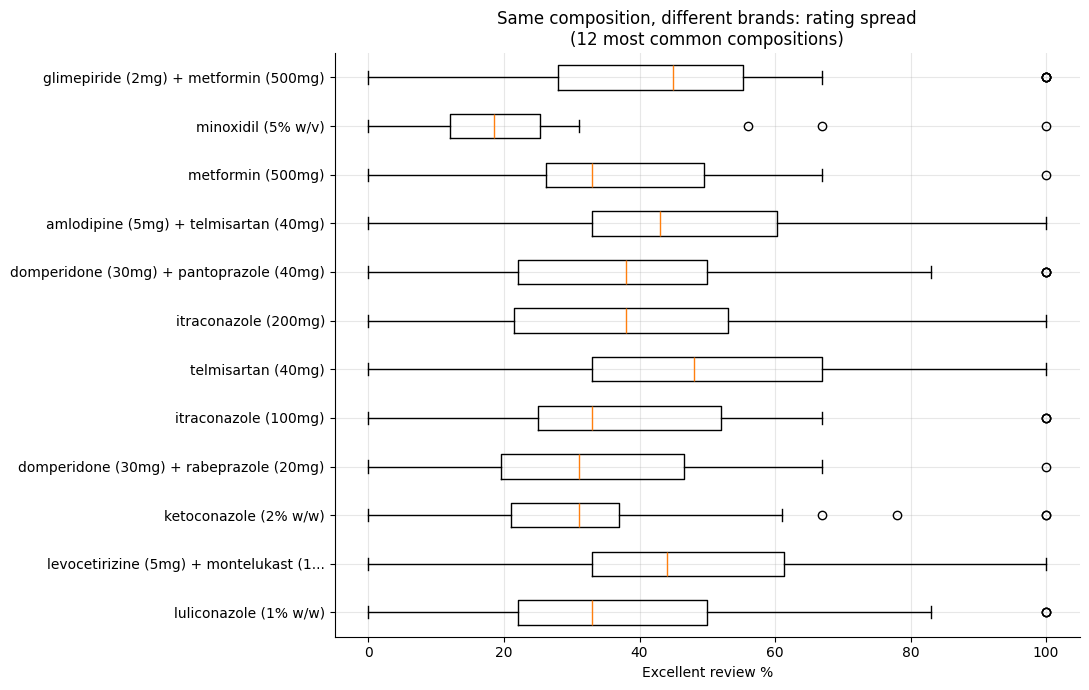

In [20]:
top = spread.head(12).index
data = [df.loc[df["composition_clean"] == c, "excellent_review"].values for c in top]
labels = [c if len(c) <= 40 else c[:37] + "..." for c in top]

fig, ax = plt.subplots(figsize=(11, 7))
ax.boxplot(data, vert=False)
ax.set_yticks(range(1, len(labels) + 1), labels)
ax.set_xlabel("Excellent review %")
ax.set_title("Same composition, different brands: rating spread\n(12 most common compositions)")
save("07_same_salt_spread")

In [21]:
# Zoom into the single most common composition
c = spread.index[0]
brands = (df[df["composition_clean"] == c]
          [["medicine_name", "manufacturer", "excellent_review", "poor_review", "net_score"]]
          .sort_values("net_score", ascending=False))
print(f"Composition: {c}  ({len(brands)} brands)")
pd.concat([brands.head(5), brands.tail(5)])

Composition: luliconazole (1% w/w)  (97 brands)


,medicine_name,manufacturer,excellent_review,poor_review,net_score
1137,Afitra-L Cream,Rapross Pharmaceuticals Pvt Ltd,100,0,100
2669,Fungerase-L Cream,Blaze Remedies,100,0,100
5015,Lulibest 1% Cream,Rockmed Pharma Pvt. Ltd.,100,0,100
5008,LT-Mac Cream,Macleods Pharmaceuticals Pvt Ltd,83,0,83
4785,Luligee Cream,Glenmark Pharmaceuticals Ltd,83,0,83
4939,Lulirx Cream,Cadila Pharmaceuticals Ltd,0,83,-83
11631,Zocon L Cream,FDC Ltd,0,83,-83
4831,Lulisol Cream,Sol Derma Pharmaceuiticals Pvt Ltd,0,100,-100
5053,Lumiza 1% Cream,HBC Dermiza Healthcare Pvt Ltd,0,100,-100
5063,Lucimac Cream,Mcastro Pharma,0,100,-100


## 8. Quick correlation check: numeric features vs. net score

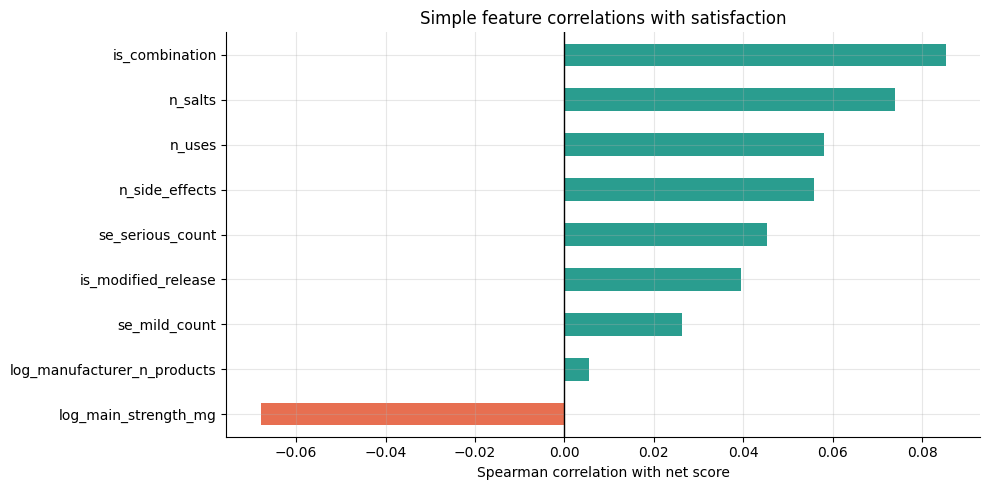

log_main_strength_mg          -0.068
log_manufacturer_n_products    0.006
se_mild_count                  0.026
is_modified_release            0.040
se_serious_count               0.045
n_side_effects                 0.056
n_uses                         0.058
n_salts                        0.074
is_combination                 0.085
Name: net_score, dtype: float64

In [22]:
num_cols = ["n_salts", "is_combination", "n_side_effects", "n_uses",
            "is_modified_release", "log_manufacturer_n_products",
            "log_main_strength_mg", "se_serious_count", "se_mild_count"]
corrs = (df[num_cols + ["net_score"]].corr(method="spearman")["net_score"]
           .drop("net_score").sort_values())

colors = ["#e76f51" if v < 0 else "#2a9d8f" for v in corrs]
ax = corrs.plot.barh(color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Spearman correlation with net score")
ax.set_title("Simple feature correlations with satisfaction")
save("08_feature_correlations")
corrs.round(3)

## Key findings (fill in after running)
Write 4–6 plain-language bullets using the numbers above. These go straight into your README.

- **Dosage form:** …
- **Therapeutic area:** …
- **Side effects:** each extra side effect / which ones hurt most …
- **Manufacturers:** …
- **Same salt, different brand:** composition explains only ___% of rating variance; brands of the identical molecule differ by a median of ___ points.
- **Limitation:** no review counts, so small-sample ratings are noisy.

**Next:** `03_modeling` / `src/train.py` tests whether these patterns hold up in a model that controls for everything at once.